# Laborator 4: Rețele Markov
Avem 5 variabile binare $A_1, A_2, A_3, A_4, A_5$ (valori 0 și 1), legate printr-un **graf neorientat**: muchiile nu au sens, ele arată doar ce variabile interacționează direct.

Muchiile din enunț:
- $A_1 - A_2$, $A_1 - A_3$
- $A_2 - A_4$, $A_2 - A_5$
- $A_3 - A_4$
- $A_4 - A_5$

Potențialul fiecărei clici maximale $C$ este:
$$\phi_C(a_C) = e^{\beta \sum_{i,j \in C,\ i<j} a_i a_j}$$

Obiectivul nostru: Să construim rețeaua în pyAgrum, să găsim clicile, să calculăm distribuția comună și starea cea mai probabilă, apoi să transformăm modelul într-un model Ising.

In [ ]:
import warnings
warnings.filterwarnings('ignore')   # ascundem avertismentele

import os
os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"

import itertools                      # generăm toate combinațiile de 0 și 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx                 # doar pentru verificarea clicilor
import pyagrum as gum                 # rețele Markov
import pyagrum.lib.notebook as gnb    # desenarea rețelei în notebook

variabile = ['A1', 'A2', 'A3', 'A4', 'A5']
muchii = [('A1', 'A2'), ('A1', 'A3'), ('A2', 'A4'), ('A2', 'A5'), ('A3', 'A4'), ('A4', 'A5')]

beta = 1   # parametrul din potențial (enunțul nu îl dă, alegem beta = 1 > 0)

# a) Graful rețelei și clicile
## a.1. Ce este o clică
O **clică** este o mulțime de noduri în care **oricare două** sunt conectate printr-o muchie.

O clică este **maximală** dacă nu mai putem adăuga niciun nod fără să pierdem această proprietate.

## a.2. Găsirea clicilor maximale (manual)
Verificăm fiecare grup posibil:
- $\{A_2, A_4, A_5\}$: există $A_2-A_4$, $A_2-A_5$ și $A_4-A_5$, deci este **triunghi**, adică o clică. Nu o putem mări: $A_1$ nu e legat de $A_4$, iar $A_3$ nu e legat de $A_2$.
- $\{A_1, A_2, A_3, A_4\}$ formează un **ciclu de 4** ($A_1-A_2-A_4-A_3-A_1$), dar **nu** e clică: lipsesc diagonalele $A_1-A_4$ și $A_2-A_3$. Deci clicile de aici sunt doar muchiile lui care nu fac parte dintr-un triunghi:
  - $\{A_1, A_2\}$
  - $\{A_1, A_3\}$
  - $\{A_3, A_4\}$
- Muchia $A_2-A_4$ este deja inclusă în triunghiul $\{A_2, A_4, A_5\}$, deci nu e clică maximală.

**Clicile maximale:**
$$\mathcal{C} = \big\{\ \{A_1,A_2\},\ \{A_1,A_3\},\ \{A_3,A_4\},\ \{A_2,A_4,A_5\}\ \big\}$$

In [2]:
# Verificăm clicile cu networkx (find_cliques găsește clicile maximale)
graf = nx.Graph(muchii)
clici = [sorted(c) for c in nx.find_cliques(graf)]
print("Clicile maximale:", sorted(clici))

Clicile maximale: [['A1', 'A2'], ['A1', 'A3'], ['A2', 'A4', 'A5'], ['A3', 'A4']]


## a.3. Construirea rețelei Markov în pyAgrum
Într-o rețea Markov, graful se construiește din **factori**: fiecare factor este definit pe o clică, iar pyAgrum leagă între ele toate variabilele care apar în același factor. Adăugăm câte un factor pentru fiecare clică maximală, deci obținem exact muchiile din enunț.

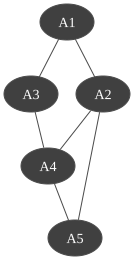

In [3]:
# Creăm rețeaua Markov și cele 5 variabile binare (valori 0 și 1)
mrf = gum.MarkovRandomField('Laborator4')
for v in variabile:
    mrf.add(gum.LabelizedVariable(v, v, 2))

# Adăugăm câte un factor pentru fiecare clică maximală
for clica in clici:
    mrf.addFactor(clica)

try:
    gnb.showMRF(mrf, view='graph')   # desenăm graful neorientat al rețelei cu pyAgrum
except Exception:
    # Dacă Graphviz nu este instalat, desenăm același graf cu networkx
    pozitii = {'A1': (0, 2), 'A2': (1, 1), 'A3': (-1, 1), 'A4': (0, 0), 'A5': (1, -1)}
    nx.draw(graf, pozitii, with_labels=True, node_size=2500, node_color='lightgreen',
            edgecolors='black', font_size=14)
    plt.title('Rețeaua Markov')
    plt.show()

### Explicații:
- `LabelizedVariable(v, v, 2)` creează o variabilă cu 2 valori: 0 și 1.
- `addFactor(clica)` adaugă un factor pe clică. Muchiile apar automat între variabilele din același factor.
- `try / except`: dacă pyAgrum nu poate desena (lipsește programul Graphviz), desenăm același graf cu networkx.
- `gnb.showMRF(mrf, view='graph')` desenează graful neorientat al rețelei (fără `view='graph'`, pyAgrum desenează graful de factori, cu factorii ca noduri mici).

## a.4. Independențele condiționate (proprietatea Markov locală)
O variabilă este independentă de toate celelalte **știind vecinii ei**:
$$X_i \perp X_{V \setminus (\{i\} \cup N(i))} \mid X_{N(i)}$$

| Variabila | Vecinii $N(i)$ | Independență |
|---|---|---|
| $A_1$ | $A_2, A_3$ | $A_1 \perp \{A_4, A_5\} \mid \{A_2, A_3\}$ |
| $A_2$ | $A_1, A_4, A_5$ | $A_2 \perp A_3 \mid \{A_1, A_4, A_5\}$ |
| $A_3$ | $A_1, A_4$ | $A_3 \perp \{A_2, A_5\} \mid \{A_1, A_4\}$ |
| $A_4$ | $A_2, A_3, A_5$ | $A_4 \perp A_1 \mid \{A_2, A_3, A_5\}$ |
| $A_5$ | $A_2, A_4$ | $A_5 \perp \{A_1, A_3\} \mid \{A_2, A_4\}$ |

In [4]:
# Verificăm vecinii fiecărui nod direct din rețeaua pyAgrum
for v in variabile:
    vecini = sorted(mrf.variable(n).name() for n in mrf.neighbours(v))
    print(f"N({v}) = {vecini}")

N(A1) = ['A2', 'A3']
N(A2) = ['A1', 'A4', 'A5']
N(A3) = ['A1', 'A4']
N(A4) = ['A2', 'A3', 'A5']
N(A5) = ['A2', 'A4']


# b) Distribuția comună și starea cea mai probabilă
## b.1. Formula (teorema Hammersley–Clifford)
Distribuția comună se scrie ca **produsul potențialelor clicilor maximale**, împărțit la constanta de normalizare $Z$:
$$P(a_1, \dots, a_5) = \frac{1}{Z} \prod_{C \in \mathcal{C}} \phi_C(a_C), \qquad Z = \sum_{a} \prod_{C \in \mathcal{C}} \phi_C(a_C)$$

## b.2. Potențialele fiecărei clici
Înlocuim formula din enunț:
- $\phi_{12}(a_1,a_2) = e^{\beta a_1 a_2}$
- $\phi_{13}(a_1,a_3) = e^{\beta a_1 a_3}$
- $\phi_{34}(a_3,a_4) = e^{\beta a_3 a_4}$
- $\phi_{245}(a_2,a_4,a_5) = e^{\beta (a_2 a_4 + a_2 a_5 + a_4 a_5)}$

Când înmulțim puteri cu aceeași bază, **adunăm exponenții**:
$$P(a) = \frac{1}{Z}\, e^{\beta\,(a_1a_2 + a_1a_3 + a_3a_4 + a_2a_4 + a_2a_5 + a_4a_5)} = \frac{1}{Z}\, e^{\beta\, S(a)}$$

$S(a)$ este suma pe **toate cele 6 muchii** (fiecare muchie apare într-o singură clică maximală).

Deoarece valorile sunt 0 sau 1, produsul $a_i a_j = 1$ doar dacă **ambele** capete sunt 1. Deci $S(a)$ = **numărul de muchii cu ambele capete egale cu 1**.

În forma Gibbs: $P(a) = \frac{1}{Z} e^{-E(a)}$, cu energia $E(a) = -\beta\, S(a)$.

In [5]:
# Completăm tabelul fiecărui factor cu valorile potențialului
def potential(valori):
    # suma a_i * a_j pe toate perechile i < j din clică
    suma = 0
    for i in range(len(valori)):
        for j in range(i + 1, len(valori)):
            suma += valori[i] * valori[j]
    return np.exp(beta * suma)

for clica in clici:
    factor = mrf.factor(clica)
    for valori in itertools.product([0, 1], repeat=len(clica)):   # toate combinațiile de 0/1
        factor[dict(zip(clica, valori))] = potential(valori)

print(mrf.factor(['A2', 'A4', 'A5']))   # exemplu: factorul triunghiului


             ║  A2               │
A4    │A5    ║0        │1        │
──────│──────║─────────│─────────│
0     │0     ║ 1.0000  │ 1.0000  │
1     │0     ║ 1.0000  │ 2.7183  │
0     │1     ║ 1.0000  │ 2.7183  │
1     │1     ║ 2.7183  │ 20.0855 │



### Explicații:
- `itertools.product([0, 1], repeat=3)` generează toate combinațiile: (0,0,0), (0,0,1), …, (1,1,1).
- Pentru fiecare combinație calculăm $e^{\beta \sum a_i a_j}$ și o punem în tabelul factorului.
- Exemplu, triunghiul cu $(1,1,1)$: suma este $1+1+1 = 3$, deci potențialul este $e^3 \approx 20.09$.
- Un potențial **nu este o probabilitate**: valorile nu au suma 1. Devin probabilități abia după împărțirea la $Z$.

## b.3. Calculul distribuției comune
Avem $2^5 = 32$ de configurații. Pentru fiecare calculăm produsul potențialelor, apoi împărțim la $Z$.

In [6]:
# Calculăm produsul potențialelor pentru fiecare dintre cele 32 de configurații
randuri = []
for config in itertools.product([0, 1], repeat=5):
    a = dict(zip(variabile, config))
    produs = 1
    for clica in clici:
        produs *= potential([a[v] for v in clica])
    S = sum(a[x] * a[y] for x, y in muchii)   # numărul de muchii cu ambele capete 1
    randuri.append({**a, 'S': S, 'produs': produs})

tabel = pd.DataFrame(randuri)
Z = tabel['produs'].sum()                  # constanta de normalizare
tabel['P'] = tabel['produs'] / Z           # probabilitatea fiecărei configurații

print(f"Z = {Z:.4f}")
print(f"Suma probabilităților = {tabel['P'].sum():.4f}")
tabel.sort_values('P', ascending=False).head(8)

Z = 706.2787
Suma probabilităților = 1.0000


,A1,A2,A3,A4,A5,S,produs,P
31,1,1,1,1,1,6,403.428793,0.571203
15,0,1,1,1,1,4,54.598150,0.077304
27,1,1,0,1,1,4,54.598150,0.077304
30,1,1,1,1,0,4,54.598150,0.077304
11,0,1,0,1,1,3,20.085537,0.028439
23,1,0,1,1,1,3,20.085537,0.028439
29,1,1,1,0,1,3,20.085537,0.028439
7,0,0,1,1,1,2,7.389056,0.010462


### Calculul manual al lui $Z$
$P$ depinde doar de $S$, deci grupăm cele 32 de configurații după $S$:

| $S$ | Număr de configurații | Contribuție la $Z$ |
|---|---|---|
| 0 | 10 | $10 \cdot e^0 = 10$ |
| 1 | 9 | $9e \approx 24.46$ |
| 2 | 6 | $6e^2 \approx 44.33$ |
| 3 | 3 | $3e^3 \approx 60.26$ |
| 4 | 3 | $3e^4 \approx 163.79$ |
| 5 | 0 | $0$ |
| 6 | 1 | $e^6 \approx 403.43$ |

$$Z = 10 + 9e + 6e^2 + 3e^3 + 3e^4 + e^6 \approx 706.28$$

$S = 5$ este imposibil: dacă un singur nod este 0, se pierd cel puțin 2 muchii (fiecare nod are cel puțin 2 vecini).

In [7]:
# Verificăm numărul de configurații pentru fiecare valoare a lui S
print(tabel.groupby('S').size())

S
0    10
1     9
2     6
3     3
4     3
6     1
dtype: int64


## b.4. Verificare cu pyAgrum
Înmulțim toți factorii rețelei și normalizăm. Trebuie să obținem același rezultat.

In [8]:
# Produsul tuturor factorilor = distribuția comună nenormalizată
comuna = mrf.factor(clici[0])
for clica in clici[1:]:
    comuna = comuna * mrf.factor(clica)

print(f"Z (pyAgrum) = {comuna.sum():.4f}")
comuna = comuna.normalize()           # împărțim la Z

config_max, p_max = comuna.argmax()   # configurația cu probabilitate maximă
print("Configurația cea mai probabilă:", config_max)
print(f"Probabilitatea ei: {p_max:.4f}")

Z (pyAgrum) = 706.2787
Configurația cea mai probabilă: [{'A1': 1, 'A2': 1, 'A3': 1, 'A4': 1, 'A5': 1}]
Probabilitatea ei: 0.5712


## b.5. Starea de probabilitate maximă
$$P(a) = \frac{1}{Z} e^{\beta S(a)}$$
Pentru $\beta > 0$, funcția exponențială este crescătoare, deci $P$ este maxim când $S$ este maxim (echivalent: energia $E = -\beta S$ este minimă).

$S$ este maxim când **toate cele 6 muchii** au ambele capete 1, adică toate variabilele sunt 1:
$$a^* = (1, 1, 1, 1, 1), \qquad S = 6, \qquad P(a^*) = \frac{e^6}{Z} = \frac{403.43}{706.28} \approx 0.5712$$

Următoarele ca probabilitate sunt configurațiile cu $S = 4$: un singur 0 pe $A_1$, $A_3$ sau $A_5$ (fiecare are doar 2 vecini, deci se pierd doar 2 muchii):
$$P = \frac{e^4}{Z} \approx 0.0773$$

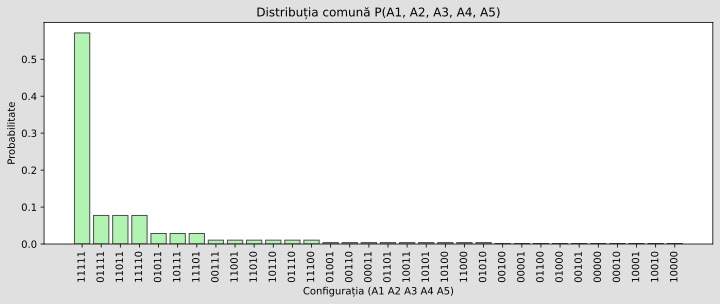

In [9]:
# Graficul probabilităților pentru toate cele 32 de configurații
tabel_sortat = tabel.sort_values('P', ascending=False)
etichete = tabel_sortat[variabile].astype(str).agg(''.join, axis=1)   # ex: '11111'

plt.figure(figsize=(12, 4))
plt.bar(etichete, tabel_sortat['P'], alpha=0.7, color='lightgreen', edgecolor='black')
plt.title('Distribuția comună P(A1, A2, A3, A4, A5)')
plt.xlabel('Configurația (A1 A2 A3 A4 A5)')
plt.ylabel('Probabilitate')
plt.xticks(rotation=90)
plt.show()

### Interpretare:
- Configurația $11111$ are singură aproximativ **57%** din probabilitate.
- Urmează configurațiile cu un singur 0 pe $A_1$, $A_3$ sau $A_5$ (~7.7% fiecare).
- Configurațiile cu $S = 0$ (nicio muchie cu ambele capete 1, de exemplu $00000$) au probabilitatea cea mai mică: $1/Z \approx 0.0014$.

Cu potențialul din enunț, modelul favorizează perechile de vecini **ambii egali cu 1**. Perechea $(0,0)$ primește același potențial ca $(0,1)$, adică $e^0 = 1$.